
# Notebook to explain the saliency map and sam segmentation

In [1]:
# Reset all variables and imports for memory management
%reset -f

# Enable automatic module reloading
%load_ext autoreload
%autoreload 2

import sys
import os

# Ensure that the project root is in the sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from torchcam.methods import LayerCAM
from segment_anything import SamAutomaticMaskGenerator
from utils.utils_setup import check_cuda_support, check_if_running_in_docker, load_models


# Check for CUDA support
try:
    gpu_name = check_cuda_support()
except RuntimeError as e:
    raise e

# Determine file paths based on environment
if check_if_running_in_docker():
    sam_checkpoint_path = "/usr/models/sam_vit_b_01ec64.pth"
    resnet_checkpoint_path = "/usr/models/resnet50-0676ba61.pth"
    class_labels_path = "imagenet_class_index.json"
    image_path = 'picture.jpeg'
else:
    sam_checkpoint_path = "../checkpoints/sam_vit_b_01ec64.pth"
    resnet_checkpoint_path = "../checkpoints/resnet50-0676ba61.pth"
    class_labels_path = "../imagenet_class_index.json"
    image_path = '../picture.jpeg'

# Load everything
try:
    sam, resnet, imagenet_labels, image_rgb = load_models(sam_checkpoint_path, resnet_checkpoint_path, class_labels_path, image_path)
except AssertionError as e:
    print(e)
    raise RuntimeError("Not all modules could be loaded")

Using GPU: NVIDIA A100-PCIE-40GB


/home/dai/araystds/miniconda3/envs/lrp/lib/python3.12/site-packages/segment_anything/build_sam.py:105: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(

All models and data loaded correctly.


In [2]:
from utils.utils_resnet import get_img_tensor, get_result, get_heatmap

# Process image with CAM
img_tensor = get_img_tensor(image_rgb)
cam_extractor = LayerCAM(resnet, resnet.layer4)
output = resnet(img_tensor)
top_index = get_result(output)
print(f"Resnet prediction: {imagenet_labels[top_index]}")
heatmap = get_heatmap(top_index, output, cam_extractor, image_rgb.shape)

# Generate masks using SAM
mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,
    pred_iou_thresh=0.86,
    stability_score_thresh=0.92,
    crop_n_layers=1,
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100  # Requires open-cv to run post-processing
)
masks = mask_generator.generate(image_rgb)

Resnet prediction: missile


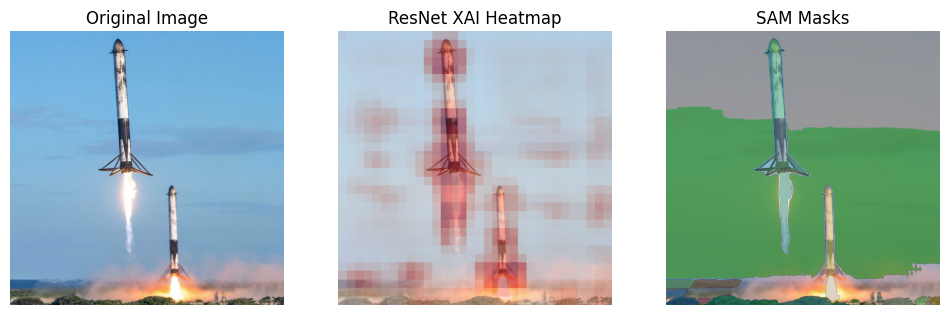

In [4]:
from utils.utils_plot import display_images_side_by_side

display_images_side_by_side(image_rgb, heatmap, masks)

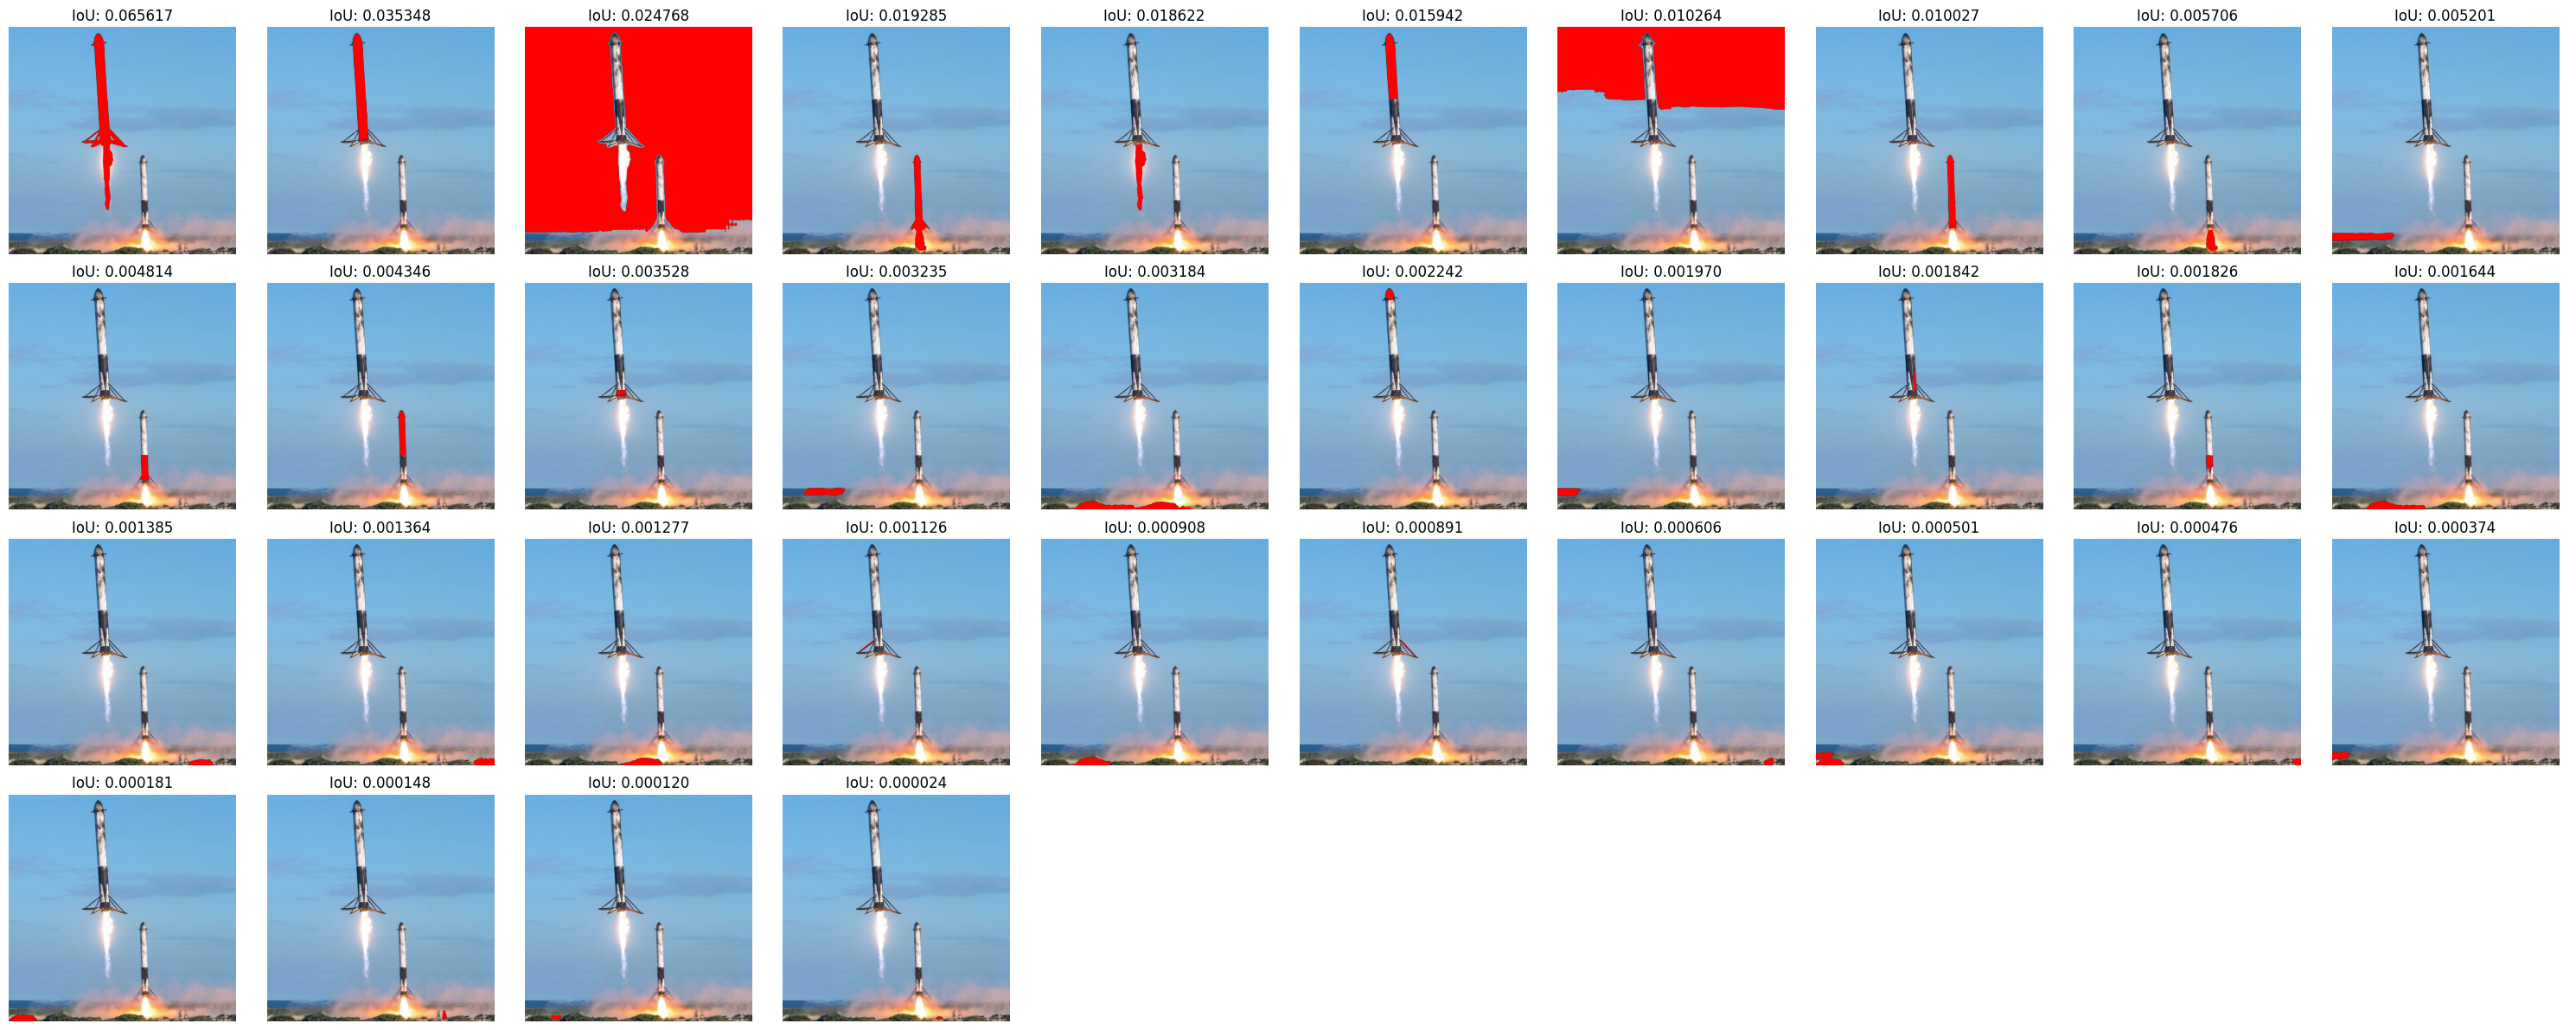

In [25]:
from utils.utils_plot import print_masks_in_grid_with_scores
from utils.utils_masks import evaluate_heatmap_alignment

# Print masks in grid
sorted_iou_scores, sorted_masks = evaluate_heatmap_alignment(masks, heatmap)
print_masks_in_grid_with_scores(image_rgb, sorted_masks, sorted_iou_scores, cols=10, base_width=3, base_height=3)

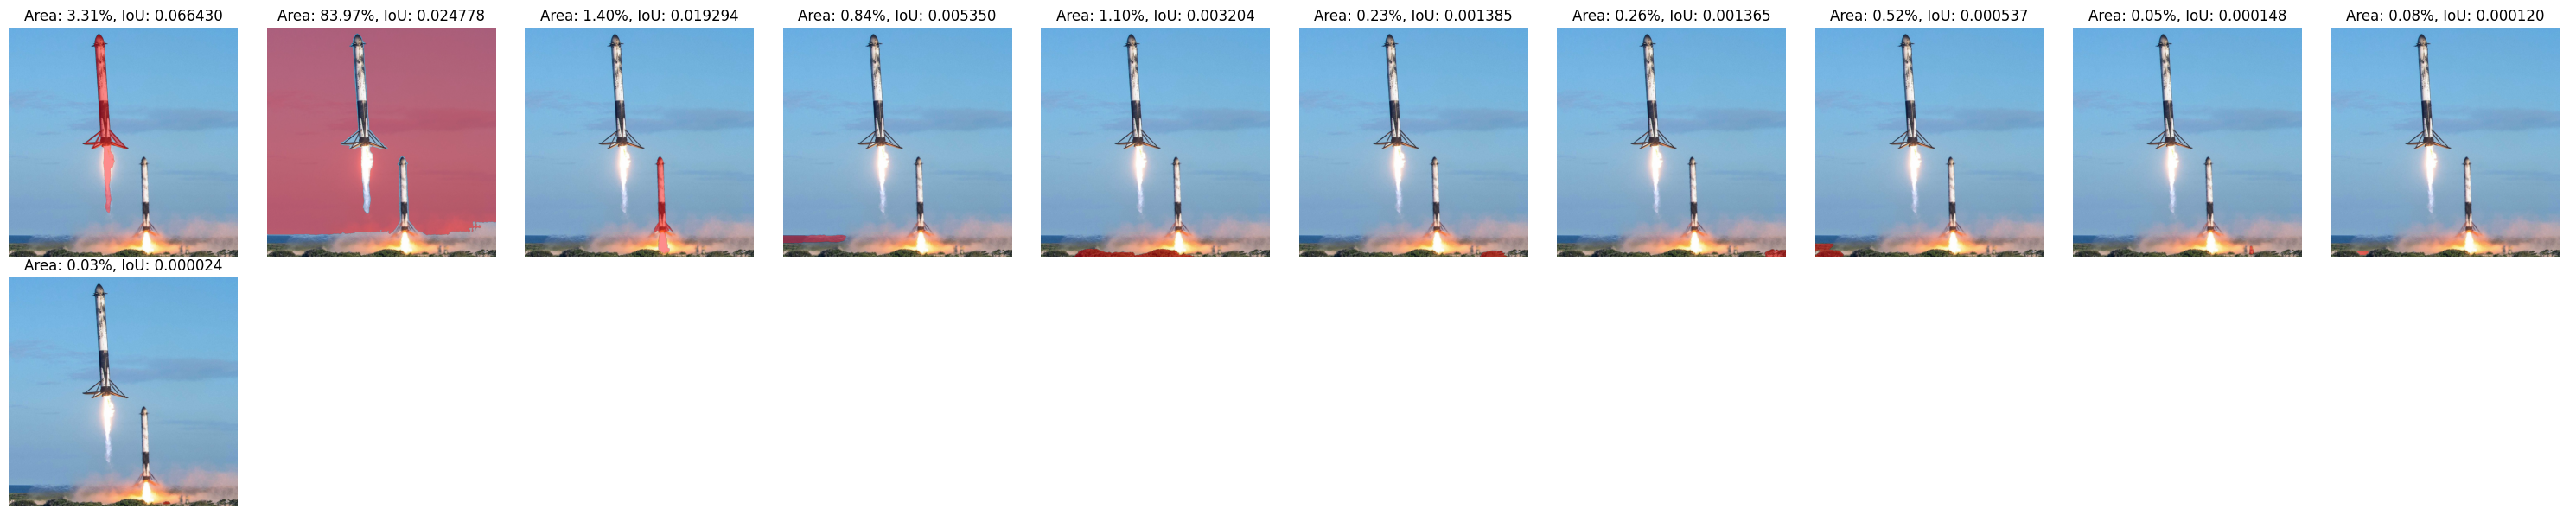

In [26]:
from utils.utils_plot import display_clusters_in_grid
from utils.utils_cluster import get_cluster

# Try to cluster the masks
sorted_combined_masks, cluster_areas, cluster_scores = get_cluster(sorted_masks, heatmap)

# Display clusters with masks highlighted on the background image
display_clusters_in_grid(image_rgb, sorted_combined_masks, cluster_areas, cluster_scores)


All Clusters:
Cluster 1 (weighted IoU: 0.066430, unique covered area: 3.31%)
Cluster 2 (weighted IoU: 0.024778, unique covered area: 83.97%)
Cluster 3 (weighted IoU: 0.019294, unique covered area: 1.40%)
Cluster 4 (weighted IoU: 0.005350, unique covered area: 0.84%)
Cluster 5 (weighted IoU: 0.003204, unique covered area: 1.10%)
Cluster 6 (weighted IoU: 0.001385, unique covered area: 0.23%)
Cluster 7 (weighted IoU: 0.001365, unique covered area: 0.26%)
Cluster 8 (weighted IoU: 0.000537, unique covered area: 0.52%)
Cluster 9 (weighted IoU: 0.000148, unique covered area: 0.05%)
Cluster 10 (weighted IoU: 0.000120, unique covered area: 0.08%)
Cluster 11 (weighted IoU: 0.000024, unique covered area: 0.03%)


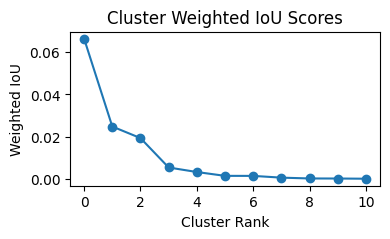

In [27]:
from utils.utils_plot import print_clusters_with_iou_scores

# Print clusters with their weighted IoU scores and plot the scores
print_clusters_with_iou_scores(sorted_combined_masks, cluster_areas, cluster_scores)

Cluster 1: Area = 3.31, Score = 0.066430
Cluster 2: Area = 83.97, Score = 0.024778
Cluster 3: Area = 1.40, Score = 0.019294


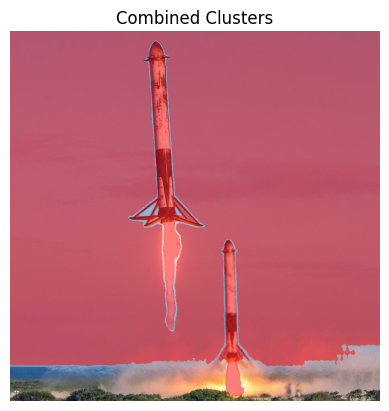

In [28]:
from utils.utils_plot import print_selected_clusters, display_combined_clusters
from utils.utils_cluster import filter_clusters_by_elbow

# Select relevant clusters (Filtered by elbow method)
relevant_clusters = filter_clusters_by_elbow(cluster_scores)
print_selected_clusters(relevant_clusters, cluster_areas, cluster_scores, sorted_combined_masks)
display_combined_clusters(relevant_clusters, sorted_combined_masks, image_rgb)